# 05 - Feed-forward Neural Network (PyTorch)

Our network and training loop are in `src/neural_net.py`. The **baseline** is the architecture
from the project description: input -> 256 -> 64 -> output, ReLU, Adam (lr 0.001), batch size 128,
60 epochs, no regularization.

Method: change **one hyperparameter at a time** from the baseline, then combine the helpful
changes. After every epoch we record train/validation loss and accuracy and keep the weights of
the best validation epoch (**early stopping**). The sweeps stop once validation accuracy hasn't
improved for 15 epochs (`patience=15`), which saves a lot of time.

In [1]:
import sys
sys.path.append("..")
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.data import get_split, N_CLASSES, SEED
from src.preprocessing import Preprocessor
from src.neural_net import train_mlp, predict_proba
from src.utils import COLORS, accuracy, Timer, save_table, save_figure, save_predictions, set_seed

set_seed()
torch.set_num_threads(1)   # these networks are small: 1 CPU thread is the fastest and gives repeatable results

BASELINE = dict(hidden=(256, 64), activation="relu", dropout=0.0, lr=1e-3, optimizer="adam",
                weight_decay=0.0, batch_size=128, epochs=60)
splits = {task: get_split(task) for task in ("image", "sentiment")}
prepared_data = {}


def prepared(task, prep_mode):
    """Train/validation features after preprocessing (fitted on the training split only)."""
    if (task, prep_mode) not in prepared_data:
        Xtr, ytr, Xva, yva = splits[task]
        prep = Preprocessor(prep_mode).fit(Xtr)
        prepared_data[(task, prep_mode)] = (prep.transform(Xtr), ytr, prep.transform(Xva), yva)
    return prepared_data[(task, prep_mode)]


def run(task, prep_mode, seed=SEED, patience=15, **changes):
    """Train one network (baseline + changes) and return a summary row and its history."""
    config = {**BASELINE, **changes}
    A, ytr, B, yva = prepared(task, prep_mode)
    with Timer() as t:
        model, history, best_epoch = train_mlp(A, ytr, B, yva, n_classes=N_CLASSES[task], seed=seed,
                                               patience=patience, **config)
    best = history.loc[history.val_acc.idxmax()]
    last = history.iloc[-1]
    row = dict(task=task, preprocessing=prep_mode, **config, best_val_acc=best.val_acc,
               best_epoch=int(best.epoch), last_val_acc=last.val_acc, last_train_acc=last.train_acc,
               fit_s=round(t.seconds, 1))
    row["hidden"] = str(row["hidden"])
    return row, history

## 1. Which preprocessing? (baseline network, all 60 epochs)

In [2]:
PREPROCESSING = {"image": ["none", "standardize", "hellinger", "hellinger+standardize"],
                 "sentiment": ["none", "standardize"]}
rows, baseline_history = [], {}
for task in splits:
    for prep_mode in PREPROCESSING[task]:
        row, history = run(task, prep_mode, patience=None)
        rows.append(row)
        baseline_history[(task, prep_mode)] = history
        print(f"{task:9s} {prep_mode:22s} best val {row['best_val_acc']:.4f} at epoch {row['best_epoch']:2d} | "
              f"last epoch: train {row['last_train_acc']:.3f}, val {row['last_val_acc']:.4f}")
prep_results = pd.DataFrame(rows)
PREP = {task: prep_results[prep_results.task == task].sort_values("best_val_acc").iloc[-1].preprocessing
        for task in splits}
print("chosen preprocessing:", PREP)

image     none                   best val 0.3155 at epoch 50 | last epoch: train 0.965, val 0.3152


image     standardize            best val 0.3330 at epoch  6 | last epoch: train 1.000, val 0.3287


image     hellinger              best val 0.2980 at epoch 45 | last epoch: train 0.980, val 0.2955


image     hellinger+standardize  best val 0.3272 at epoch 26 | last epoch: train 1.000, val 0.3220


sentiment none                   best val 0.6792 at epoch  3 | last epoch: train 1.000, val 0.6146


sentiment standardize            best val 0.6725 at epoch  1 | last epoch: train 1.000, val 0.6304
chosen preprocessing: {'image': 'standardize', 'sentiment': 'none'}


Standardizing helps a little on images (33.3% vs 31.6% raw). The Hellinger transform, which helped
k-NN, does *not* help the network (29.8%): a network can learn its own rescaling of each feature,
while k-NN's distances depend directly on the scale. For sentiment, raw and standardized are within
noise (67.9% vs 67.3%).

## 2. Learning curves of the baseline
Training accuracy keeps going up while validation loss turns upward after a few epochs: that is
where the network stops learning general patterns and starts memorizing the training set.

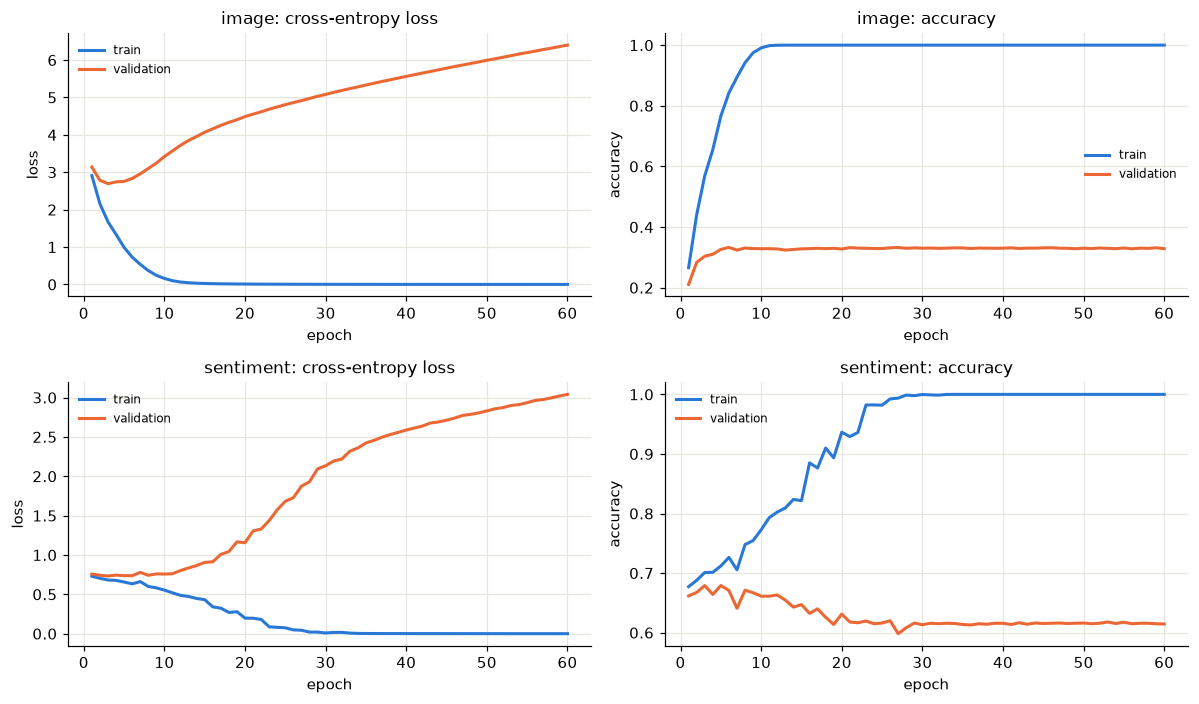

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for i, task in enumerate(splits):
    h = baseline_history[(task, PREP[task])]
    axes[i, 0].plot(h.epoch, h.train_loss, color=COLORS[0], label="train")
    axes[i, 0].plot(h.epoch, h.val_loss, color=COLORS[1], label="validation")
    axes[i, 0].set_title(f"{task}: cross-entropy loss")
    axes[i, 0].set_ylabel("loss")
    axes[i, 1].plot(h.epoch, h.train_acc, color=COLORS[0], label="train")
    axes[i, 1].plot(h.epoch, h.val_acc, color=COLORS[1], label="validation")
    axes[i, 1].set_title(f"{task}: accuracy")
    axes[i, 1].set_ylabel("accuracy")
    for ax in axes[i]:
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "05_nn_baseline_curves")
plt.show()

## 3. One hyperparameter at a time
`last_*` = the epoch where training stopped (15 epochs after the best one, or epoch 60).

In [4]:
SWEEPS = {
    "lr": [dict(lr=1e-2), dict(lr=1e-3), dict(lr=1e-4)],
    "hidden": [dict(hidden=h) for h in [(), (64,), (256,), (256, 64), (512, 256), (1024, 512)]],
    "activation": [dict(activation=a) for a in ("relu", "gelu", "tanh", "sigmoid")],
    "dropout": [dict(dropout=p) for p in (0.0, 0.2, 0.5)],
    "weight_decay": [dict(weight_decay=w) for w in (0.0, 1e-5, 1e-4, 1e-3)],
    "batch_size": [dict(batch_size=b) for b in (32, 128, 512)],
    "optimizer": [dict(optimizer="adam", lr=1e-3), dict(optimizer="sgd", lr=1e-2)],
}
rows = []
for task in splits:
    for name, variants in SWEEPS.items():
        for changes in variants:
            row, _ = run(task, PREP[task], **changes)
            row["sweep"] = name
            row["setting"] = ", ".join(f"{k}={v}" for k, v in changes.items())
            rows.append(row)
        print(task, name, "done")
sweeps = pd.DataFrame(rows)
save_table(sweeps, "nn_sweeps")
columns = ["sweep", "setting", "best_val_acc", "best_epoch", "last_val_acc", "last_train_acc", "fit_s"]
for task in splits:
    print(f"\n=== {task} ===")
    print(sweeps[sweeps.task == task][columns].round(4).to_string(index=False))

image lr done


image hidden done


image activation done


image dropout done


image weight_decay done


image batch_size done


... (4 outputs left out)

sentiment dropout done


sentiment weight_decay done


sentiment batch_size done


sentiment optimizer done

=== image ===
       sweep                  setting  best_val_acc  best_epoch  last_val_acc  last_train_acc  fit_s
          lr                  lr=0.01        0.2125          22        0.1920          0.6001   23.4
          lr                 lr=0.001        0.3330           6        0.3322          1.0000   13.4
          lr                lr=0.0001        0.3288          57        0.3285          0.9238   39.8
      hidden                hidden=()        0.3147           7        0.2935          0.6011    7.4
      hidden             hidden=(64,)        0.3030           7        0.2735          0.7765    8.3
      hidden            hidden=(256,)        0.3468           5        0.3442          1.0000   12.1
      hidden         hidden=(256, 64)        0.3330           6        0.3322          1.0000   13.8
      hidden        hidden=(512, 256)        0.3682          24        0.3632          1.0000   48.4
      hidden       hidden=(1024, 512)        0.3872

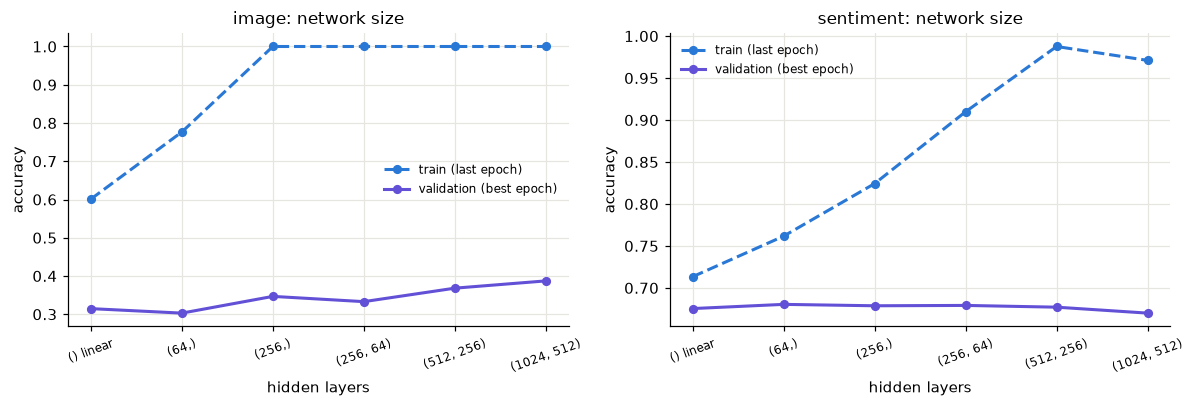

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    r = sweeps[(sweeps.task == task) & (sweeps.sweep == "hidden")]
    labels = [s.replace("hidden=", "").replace("()", "() linear") for s in r.setting]
    x = np.arange(len(r))
    ax.plot(x, r.last_train_acc, color=COLORS[0], linestyle="--", marker="o", label="train (last epoch)")
    ax.plot(x, r.best_val_acc, color=COLORS[6], marker="o", label="validation (best epoch)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, fontsize=8)
    ax.set_xlabel("hidden layers")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: network size")
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "05_nn_hidden_size")
plt.show()

* **Learning rate:** 0.01 is too big on images (21%, the updates overshoot); 0.0001 reaches about
  the same accuracy as 0.001 but needs ~10x more epochs.
* **Size:** on images wider networks help (linear 31.5%, 256-64 33.3%, 1024-512 38.7%). On sentiment
  *every* size, even no hidden layer at all (= logistic regression, 67.5%), lands at 67-68%: extra
  capacity only adds overfitting.
* **Activation:** ReLU/GELU beat tanh/sigmoid on images; no difference on sentiment.
* **Dropout / weight decay:** dropout hurts on images, but on sentiment it slows down overfitting
  (last-epoch accuracy 66.6% with dropout 0.5 vs 62.6% without) even if the best epoch is not better.
* **Batch size / optimizer:** small effects (about 1 point or less).

Every sentiment variation is within about 1 point of the others, which is within validation noise.

## 4. Combining the helpful settings
A small grid over network size and regularization (80 epochs max).

In [6]:
GRID = [dict(hidden=h, dropout=p, weight_decay=w)
        for h in ((512, 256), (1024, 512)) for p in (0.3, 0.5) for w in (0.0, 1e-4)]
rows = []
for task in splits:
    for changes in GRID:
        row, _ = run(task, PREP[task], epochs=80, **changes)
        row["setting"] = ", ".join(f"{k}={v}" for k, v in changes.items())
        rows.append(row)
        print(f"{task:9s} {row['setting']:55s} best val {row['best_val_acc']:.4f} at epoch {row['best_epoch']}")
grid = pd.DataFrame(rows)
save_table(grid, "nn_grid")

image     hidden=(512, 256), dropout=0.3, weight_decay=0.0        best val 0.3683 at epoch 26


image     hidden=(512, 256), dropout=0.3, weight_decay=0.0001     best val 0.3715 at epoch 10


image     hidden=(512, 256), dropout=0.5, weight_decay=0.0        best val 0.3593 at epoch 26


image     hidden=(512, 256), dropout=0.5, weight_decay=0.0001     best val 0.3560 at epoch 37


image     hidden=(1024, 512), dropout=0.3, weight_decay=0.0       best val 0.3845 at epoch 39


image     hidden=(1024, 512), dropout=0.3, weight_decay=0.0001    best val 0.3817 at epoch 44


... (6 outputs left out)

sentiment hidden=(1024, 512), dropout=0.3, weight_decay=0.0       best val 0.6808 at epoch 5


sentiment hidden=(1024, 512), dropout=0.3, weight_decay=0.0001    best val 0.6787 at epoch 6


sentiment hidden=(1024, 512), dropout=0.5, weight_decay=0.0       best val 0.6787 at epoch 12


sentiment hidden=(1024, 512), dropout=0.5, weight_decay=0.0001    best val 0.6771 at epoch 5


On images no combination beats the best single change (1024-512, no dropout: 38.7%). On
sentiment the best cell (512-256, dropout 0.5, weight decay 1e-4: 68.1%) is within noise of
everything else.

## 5. Final network: different random seeds, and an ensemble of 5
We take the best setting from sections 3-4 and train it with 5 different seeds (different initial
weights and batch order). Averaging the 5 networks' probabilities is an **ensemble**.

In [7]:
TUNED = {}
for task in splits:
    candidates = pd.concat([grid[grid.task == task], sweeps[sweeps.task == task]])
    b = candidates.sort_values("best_val_acc", ascending=False, kind="stable").iloc[0]
    TUNED[task] = dict(hidden=ast.literal_eval(b.hidden), activation=b.activation, dropout=float(b.dropout),
                       lr=float(b.lr), optimizer=b.optimizer, weight_decay=float(b.weight_decay),
                       batch_size=int(b.batch_size), epochs=int(b.epochs))
    print(task, "tuned:", TUNED[task])

rows = []
for task in splits:
    A, ytr, B, yva = prepared(task, PREP[task])
    probas, best_epochs, seed_accs = [], [], []
    for s in range(5):
        with Timer() as t:
            model, history, best_epoch = train_mlp(A, ytr, B, yva, n_classes=N_CLASSES[task], seed=SEED + s,
                                                   patience=15, **TUNED[task])
        with Timer() as t_pred:
            p = predict_proba(model, B)
        probas.append(p)
        best_epochs.append(best_epoch)
        seed_accs.append(accuracy(yva, p.argmax(1)))
        if s == 0:
            first = dict(proba=p, fit_seconds=t.seconds, predict_seconds=t_pred.seconds, history=history,
                         train_acc=history.loc[history.epoch == best_epoch, "train_acc"].item())
    ensemble = np.mean(probas, axis=0)
    config = {**TUNED[task], "hidden": list(TUNED[task]["hidden"])}
    info = dict(model="Neural Network", config=config, preprocessing=PREP[task], val_acc=seed_accs[0],
                train_acc=first["train_acc"], best_epochs_5_seeds=[int(e) for e in best_epochs],
                seeds_mean_acc=float(np.mean(seed_accs)), fit_seconds=first["fit_seconds"],
                predict_seconds=first["predict_seconds"])
    save_predictions(task, "nn", first["proba"].argmax(1), first["proba"], info)
    save_predictions(task, "nn5", ensemble.argmax(1), ensemble,
                     dict(info, model="5-network ensemble", val_acc=accuracy(yva, ensemble.argmax(1))))
    first["history"].to_csv(f"../results/tables/nn_tuned_history_{task}.csv", index=False)
    rows.append(dict(task=task, seed_mean=np.mean(seed_accs), seed_std=np.std(seed_accs),
                     seed_min=np.min(seed_accs), seed_max=np.max(seed_accs),
                     ensemble_of_5=accuracy(yva, ensemble.argmax(1)), best_epochs=best_epochs))
pd.DataFrame(rows).round(4)

image tuned: {'hidden': (1024, 512), 'activation': 'relu', 'dropout': 0.0, 'lr': 0.001, 'optimizer': 'adam', 'weight_decay': 0.0, 'batch_size': 128, 'epochs': 60}
sentiment tuned: {'hidden': (512, 256), 'activation': 'relu', 'dropout': 0.5, 'lr': 0.001, 'optimizer': 'adam', 'weight_decay': 0.0001, 'batch_size': 128, 'epochs': 80}


,task,seed_mean,seed_std,seed_min,seed_max,ensemble_of_5,best_epochs
0,image,0.3858,0.0039,0.3785,0.3898,0.4078,"[46, 13, 35, 10, 38]"
1,sentiment,0.6806,0.0016,0.6783,0.6829,0.6792,"[8, 9, 12, 9, 5]"


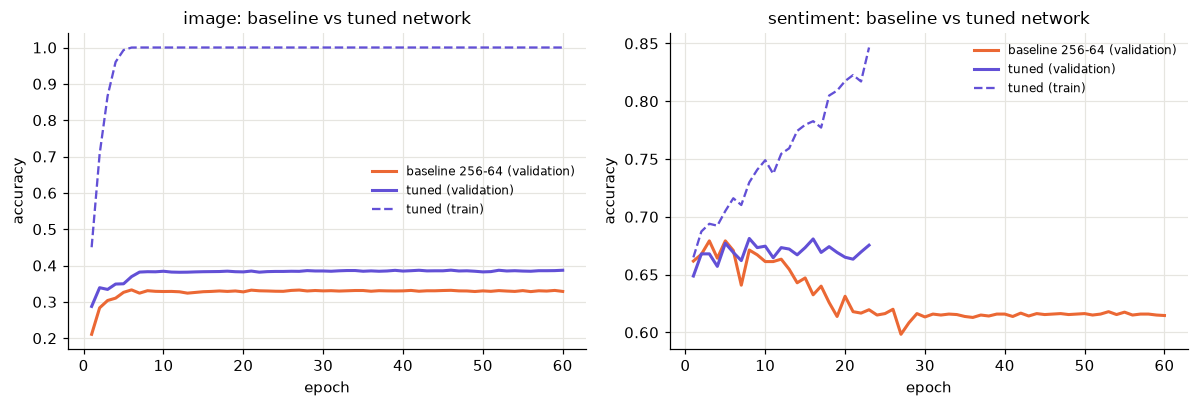

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    h = pd.read_csv(f"../results/tables/nn_tuned_history_{task}.csv")
    hb = baseline_history[(task, PREP[task])]
    ax.plot(hb.epoch, hb.val_acc, color=COLORS[1], label="baseline 256-64 (validation)")
    ax.plot(h.epoch, h.val_acc, color=COLORS[6], label="tuned (validation)")
    ax.plot(h.epoch, h.train_acc, color=COLORS[6], linestyle="--", linewidth=1.5, label="tuned (train)")
    ax.set_xlabel("epoch")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: baseline vs tuned network")
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "05_nn_tuned_vs_baseline")
plt.show()

**Final networks.** Images: 38.6% +- 0.4 over 5 seeds, and the 5-network ensemble gets 40.8%
(ensembles help most when the single models are unstable). Sentiment: 68.1% +- 0.2, ensemble 67.9%.

**Why is the network so much worse than k-NN on images (39% vs 61%)?** It memorizes the training
set within ~10 epochs but has to squeeze each class into one smooth decision function. Notebook 02
showed image classes are made of many small groups of near-relatives; "this looks like training
image #8,123" is exactly what k-NN does, and what a network does poorly with 320 images per class.